# 🎯 Estimating π with random points

A circle of radius 1 inside the square $[-1, 1]^2$ covers $\pi/4$ of it. Throw points at the square uniformly at random, and the share that lands inside the circle approaches $\pi/4$:

$$\pi \approx 4 \cdot \frac{\text{points inside the circle}}{\text{all points}}$$

Everything below uses the `montecarlo_pi` package from this repository, the same code that runs in the [browser version](https://pero-grubac.github.io/Monte-Carlo-based-Pi-Calculator-py/).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

from montecarlo_pi import Simulation, convergence, estimate_pi, samples_for_decimals
from montecarlo_pi.plotting import plot_convergence, plot_points

plt.rcParams["figure.dpi"] = 110

## One run

5,000 points with a fixed seed, so the run can be repeated exactly.

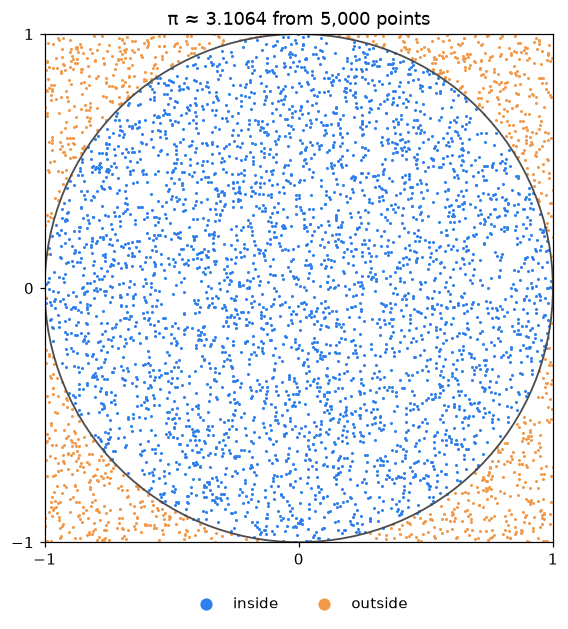

In [2]:
simulation = Simulation(seed=1)
points = simulation.run(5_000, capture=5_000)

plot_points(points, size=4)
plt.title(f"π ≈ {simulation.estimate.pi:.4f} from {simulation.estimate.total:,} points")
plt.show()

## More points, a better estimate

The 95% interval says how far from the estimate π can still be. It shrinks with $1/\sqrt{N}$: a hundred times more points for one more correct decimal.

In [3]:
print(f"{'points':>13}  {'estimate':>12}  {'error':>10}  {'95% interval':>14}  decimals")
for exponent in range(2, 9):
    e = estimate_pi(10**exponent, seed=1)
    half = (e.interval95[1] - e.interval95[0]) / 2
    print(f"{e.total:>13,}  {e.pi:>12.8f}  {e.error:>+10.2e}  {'± ' + format(half, '.2e'):>14}  {e.matching_decimals}")

       points      estimate       error    95% interval  decimals
          100    3.36000000   +2.18e-01      ± 2.87e-01  0
        1,000    3.10400000   -3.76e-02      ± 1.03e-01  1
       10,000    3.11240000   -2.92e-02      ± 3.26e-02  1
      100,000    3.14324000   +1.65e-03      ± 1.02e-02  2
    1,000,000    3.14016000   -1.43e-03      ± 3.22e-03  2


   10,000,000    3.14105840   -5.34e-04      ± 1.02e-03  3


  100,000,000    3.14159368   +1.03e-06      ± 3.22e-04  5


## Convergence

The estimate of a single run against the number of points. The shaded band, $\pm 1.96 \cdot \sqrt{\pi(4-\pi)} / \sqrt{N}$, is where 95% of all runs are.

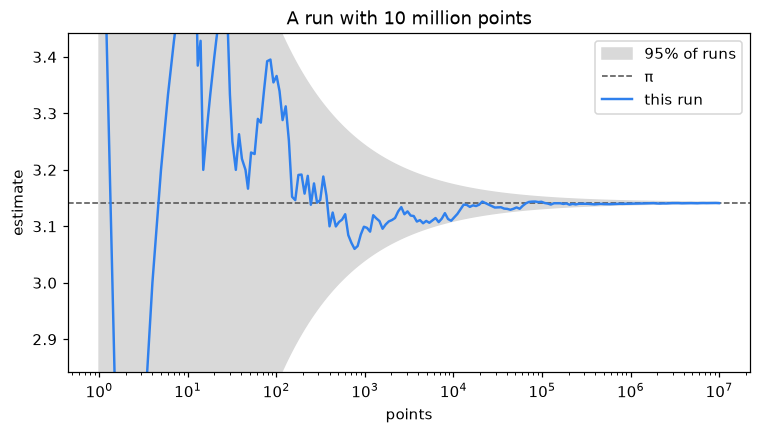

In [4]:
counts, estimates = convergence(10**7, seed=1)

ax = plot_convergence(counts, estimates)
ax.set_title("A run with 10 million points")
plt.show()

## How many points for $d$ decimals?

Points needed to be 95% sure that the first $d$ decimals are right, that is, that the error is below half a unit of the $d$-th decimal.

In [5]:
def duration(seconds):
    for unit, size in [("years", 365 * 86400), ("days", 86400), ("hours", 3600), ("minutes", 60)]:
        if seconds >= size:
            return f"{seconds / size:,.1f} {unit}"
    return f"{seconds:.2f} seconds"


speed = 45e6  # points per second with NumPy on one core
for d in range(1, 9):
    n = samples_for_decimals(d)
    print(f"{d} decimals: {n:8.1e} points, {duration(n / speed):>15}")

1 decimals:  4.1e+03 points,    0.00 seconds
2 decimals:  4.1e+05 points,    0.01 seconds
3 decimals:  4.1e+07 points,    0.92 seconds
4 decimals:  4.1e+09 points,     1.5 minutes
5 decimals:  4.1e+11 points,       2.6 hours
6 decimals:  4.1e+13 points,       10.7 days
7 decimals:  4.1e+15 points,       2.9 years
8 decimals:  4.1e+17 points,     292.0 years


## Until the decimals match

Drawing until the estimate's first four decimals equal π's often stops far earlier than the table above promises. A random estimate wanders through the right window by chance, so a match is luck, not precision.

In [6]:
for seed in range(1, 9):
    simulation = Simulation(seed)
    matched, _ = simulation.run_until_decimals(4, budget=10**9)
    e = simulation.estimate
    print(f"seed {seed}: {e.pi:.8f} after {e.total:>13,} points" + ("" if matched else "  (no match)"))

seed 1: 3.14152104 after        20,315 points
seed 2: 3.14155251 after           219 points
seed 3: 3.14157973 after           671 points
seed 4: 3.14151347 after         9,356 points


seed 5: 3.14150178 after       293,438 points


seed 6: 3.14156171 after         1,985 points
seed 7: 3.14150395 after        24,070 points


seed 8: 3.14159978 after     6,447,291 points


## Many runs

A thousand runs of 10,000 points each. The estimates follow a normal distribution centred on π, with the standard deviation $\sqrt{\pi(4-\pi)/N}$.

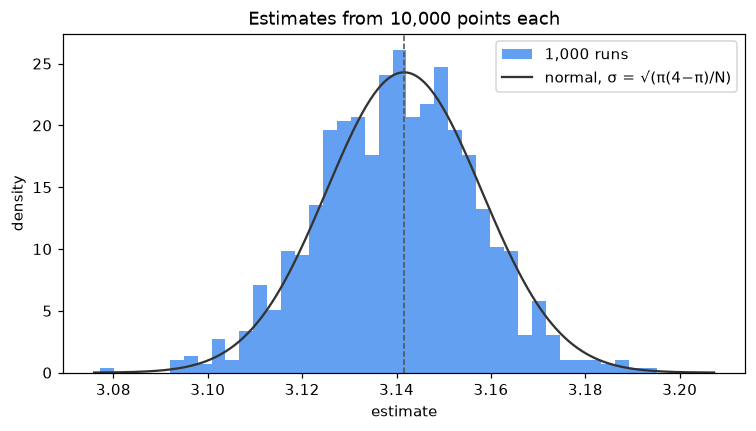

mean 3.14013, standard deviation 0.01651 (theory 0.01642)


In [7]:
n = 10_000
estimates = np.array([estimate_pi(n, seed=s).pi for s in range(1_000)])
sigma = math.sqrt(math.pi * (4 - math.pi) / n)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(estimates, bins=40, density=True, color="#2F80ED", alpha=0.75, label="1,000 runs")
x = np.linspace(math.pi - 4 * sigma, math.pi + 4 * sigma, 300)
normal = np.exp(-((x - math.pi) ** 2) / (2 * sigma**2)) / (sigma * math.sqrt(2 * math.pi))
ax.plot(x, normal, color="0.2", label="normal, σ = √(π(4−π)/N)")
ax.axvline(math.pi, color="0.3", linestyle="--", linewidth=1)
ax.set(xlabel="estimate", ylabel="density", title=f"Estimates from {n:,} points each")
ax.legend()
plt.show()

print(f"mean {estimates.mean():.5f}, standard deviation {estimates.std():.5f} (theory {sigma:.5f})")